In [ ]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Model Evaluation
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


df = pd.read_csv("customer_sales_1000.csv")

df.head()
df.info()

print(df.columns)

df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Customer_ID       1000 non-null   int64 
 1   Age               1000 non-null   int64 
 2   Gender            1000 non-null   object
 3   City              1000 non-null   object
 4   Product_Category  1000 non-null   object
 5   Quantity          1000 non-null   int64 
 6   Price             1000 non-null   int64 
 7   Purchase_Date     1000 non-null   object
 8   Total_Sales       1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB
Index(['Customer_ID', 'Age', 'Gender', 'City', 'Product_Category', 'Quantity',
       'Price', 'Purchase_Date', 'Total_Sales'],
      dtype='object')


,Customer_ID,Age,Quantity,Price,Total_Sales
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,1500.500000,41.234000,5.409000,25312.104000,137848.339000
std,288.819436,14.080963,2.920316,14077.796377,116109.827322
min,1001.000000,18.000000,1.000000,500.000000,627.000000
25%,1250.750000,29.000000,3.000000,13749.750000,43953.500000
50%,1500.500000,41.000000,5.000000,25002.000000,101076.500000
75%,1750.250000,54.000000,8.000000,37608.250000,206515.000000
max,2000.000000,65.000000,10.000000,49989.000000,499360.000000


In [ ]:
df.isnull().sum()
print(df.duplicated().sum())
df = df.drop_duplicates()

0


## **EDA**

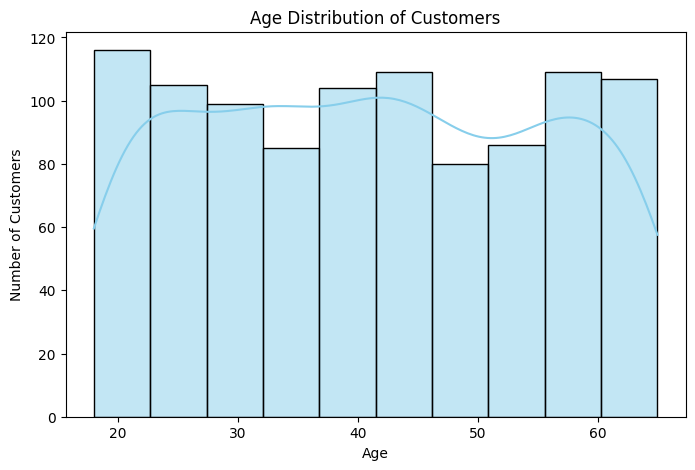

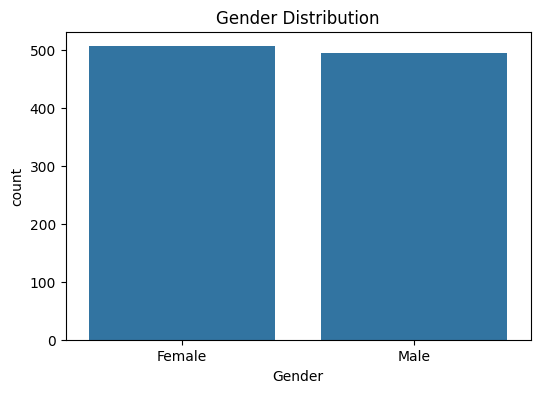

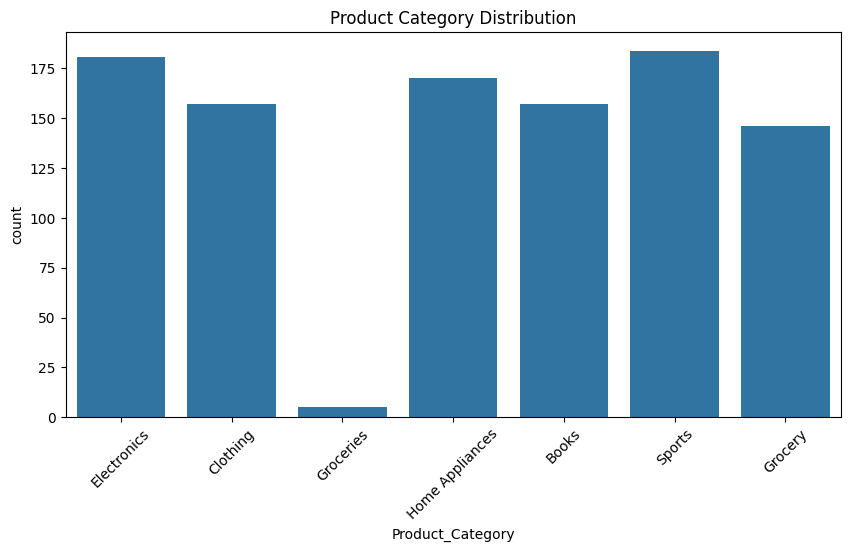

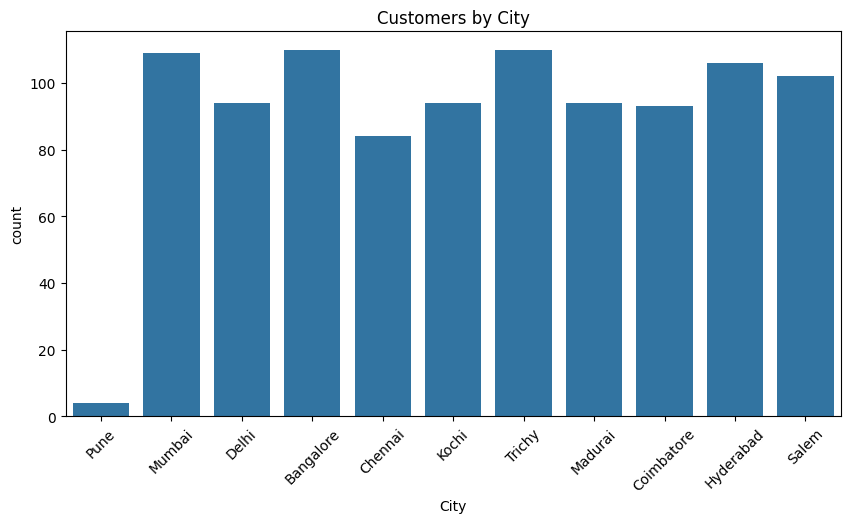

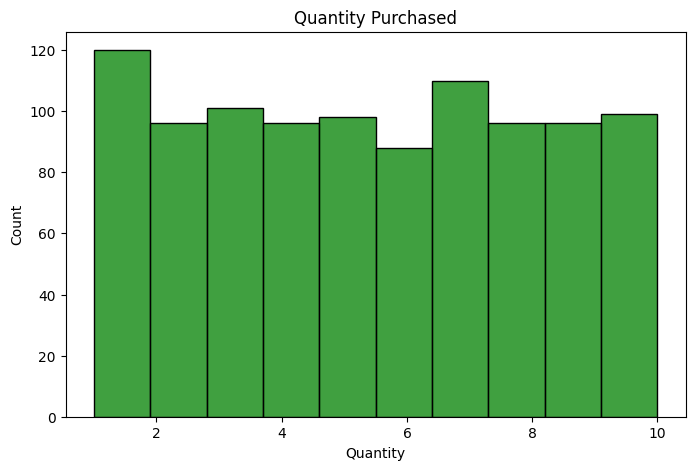

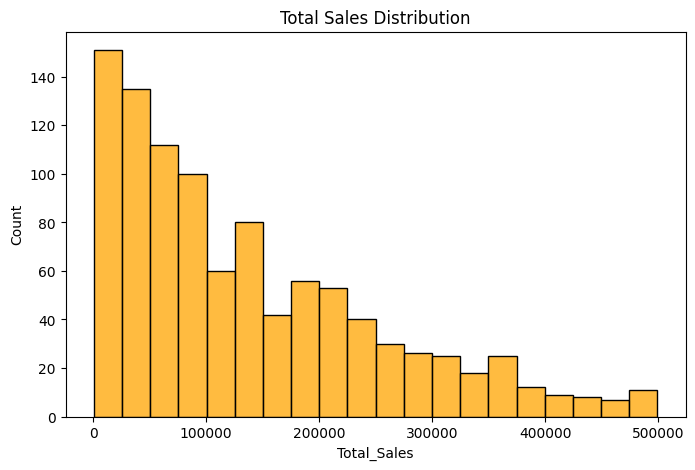

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df['Age'], bins=10, kde=True, color='skyblue')

plt.title("Age Distribution of Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

plt.figure(figsize=(6,4))
sns.countplot(x='Gender', data=df)

plt.title("Gender Distribution")

plt.show()

plt.figure(figsize=(10,5))
sns.countplot(x='Product_Category', data=df)

plt.title("Product Category Distribution")
plt.xticks(rotation=45)

plt.show()

plt.figure(figsize=(10,5))
sns.countplot(x='City', data=df)

plt.title("Customers by City")
plt.xticks(rotation=45)

plt.show()
plt.figure(figsize=(8,5))
sns.histplot(df['Quantity'], bins=10, color='green')

plt.title("Quantity Purchased")

plt.show()

plt.figure(figsize=(8,5))
sns.histplot(df['Total_Sales'], bins=20, color='orange')

plt.title("Total Sales Distribution")

plt.show()

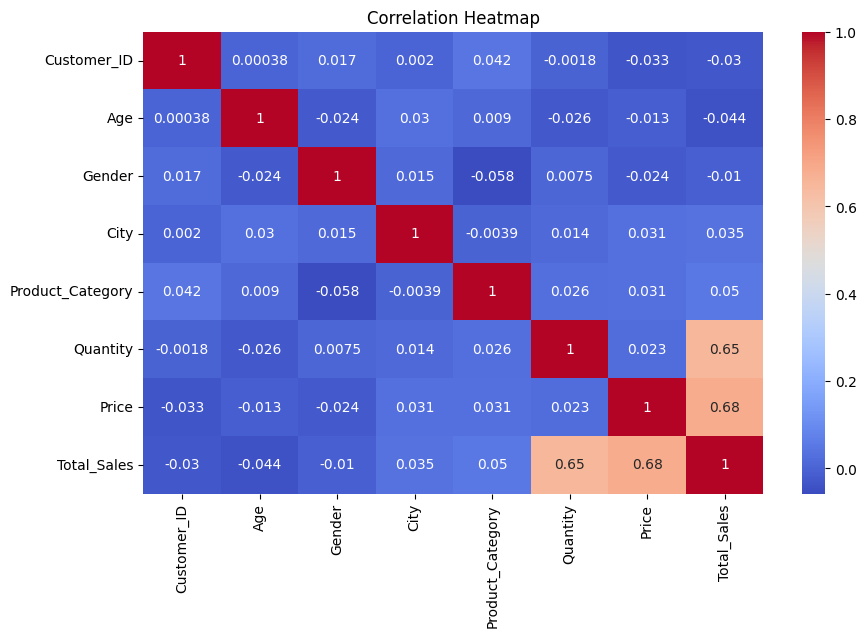

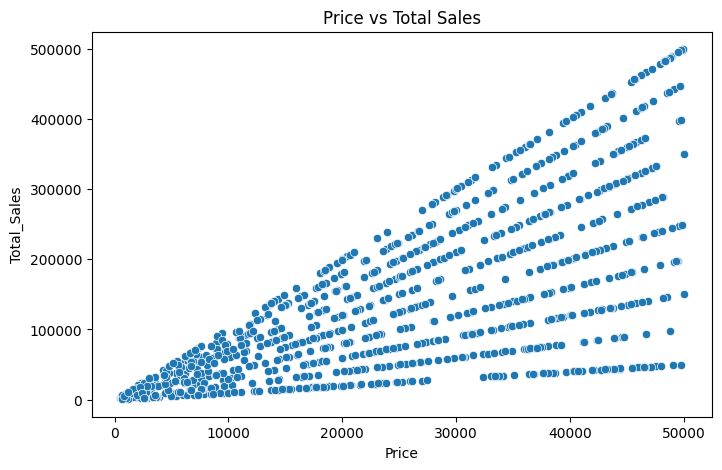

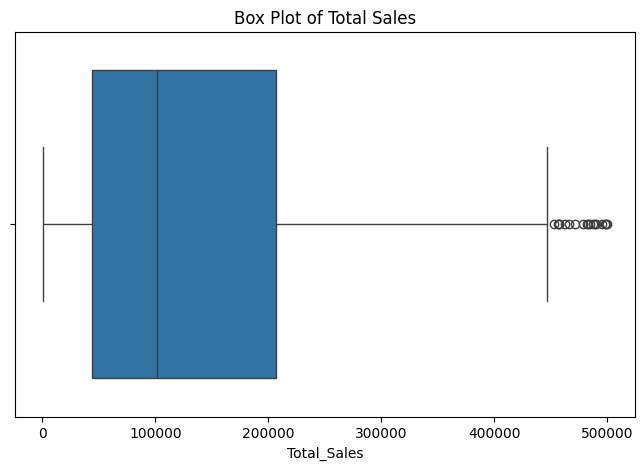

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['Gender'] = le.fit_transform(df['Gender'])
df['City'] = le.fit_transform(df['City'])
df['Product_Category'] = le.fit_transform(df['Product_Category'])

plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap='coolwarm')

plt.title("Correlation Heatmap")

plt.show()
plt.figure(figsize=(8,5))
sns.scatterplot(x='Price',
                y='Total_Sales',
                data=df)

plt.title("Price vs Total Sales")

plt.show()

plt.figure(figsize=(8,5))
sns.boxplot(x=df['Total_Sales'])

plt.title("Box Plot of Total Sales")

plt.show()

DATA PREPROCESSING AND ML


In [ ]:
# Features (Independent Variables)
X = df[['Age', 'Gender', 'City', 'Product_Category', 'Quantity', 'Price']]

# Target (Dependent Variable)
y = df['Total_Sales']
print(X.head())
print(y.head())
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

   Age  Gender  City  Product_Category  Quantity  Price
0   25       0     8                 2         1  15000
1   30       1     7                 1         2   2000
2   35       0     3                 3         5    500
3   40       1     0                 2         1  20000
4   28       0     8                 1         3   2500
0    15000
1     4000
2     2500
3    20000
4     7500
Name: Total_Sales, dtype: int64
Training Data: (800, 6)
Testing Data: (200, 6)


In [ ]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("Linear Regression Results")

print("MAE :", mean_absolute_error(y_test, y_pred_lr))

print("MSE :", mean_squared_error(y_test, y_pred_lr))

print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_lr)))

print("R2 Score :", r2_score(y_test, y_pred_lr))

Linear Regression Results
MAE : 33421.51327053019
MSE : 1807009980.8914306
RMSE : 42508.94001138385
R2 Score : 0.8770231070996263


In [ ]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(random_state=42)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("Decision Tree Results")

print("MAE :", mean_absolute_error(y_test, y_pred_dt))

print("MSE :", mean_squared_error(y_test, y_pred_dt))

print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_dt)))

print("R2 Score :", r2_score(y_test, y_pred_dt))

Decision Tree Results
MAE : 3923.455
MSE : 37733830.745
RMSE : 6142.786887480307
R2 Score : 0.9974320068448325


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
print("Random Forest Results")

print("MAE :", mean_absolute_error(y_test, y_pred_rf))

print("MSE :", mean_squared_error(y_test, y_pred_rf))

print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred_rf)))

print("R2 Score :", r2_score(y_test, y_pred_rf))

Random Forest Results
MAE : 3125.150199999999
MSE : 21879111.615793996
RMSE : 4677.511263032297
R2 Score : 0.9985110070257589


               Model  R2 Score
0  Linear Regression  0.877023
1      Decision Tree  0.997432
2      Random Forest  0.998511


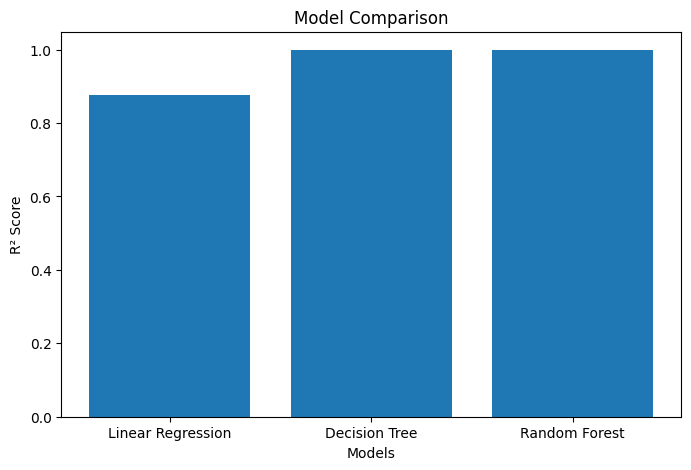

In [ ]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'R2 Score': [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_pred_dt),
        r2_score(y_test, y_pred_rf)
    ]
})

print(results)

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.bar(results['Model'], results['R2 Score'])

plt.title("Model Comparison")

plt.xlabel("Models")

plt.ylabel("R² Score")

plt.show()

In [ ]:
new_customer = pd.DataFrame({
    'Age': [30],
    'Gender': [1],      # Male = 1, Female = 0
    'City': [2],
    'Product_Category': [1],
    'Quantity': [3],
    'Price': [15000]
})

prediction = rf.predict(new_customer)

print("Predicted Total Sales = ₹", prediction[0])

Predicted Total Sales = ₹ 46100.37
